<a href="https://colab.research.google.com/github/emirbekk08/data-analysis-practice/blob/main/Untitled3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install umap-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

# Загружаем датасет (30 числовых признаков >= 10 по условию)
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print(f"Количество объектов: {X.shape[0]}, количество признаков: {X.shape[1]}")


Количество объектов: 569, количество признаков: 30


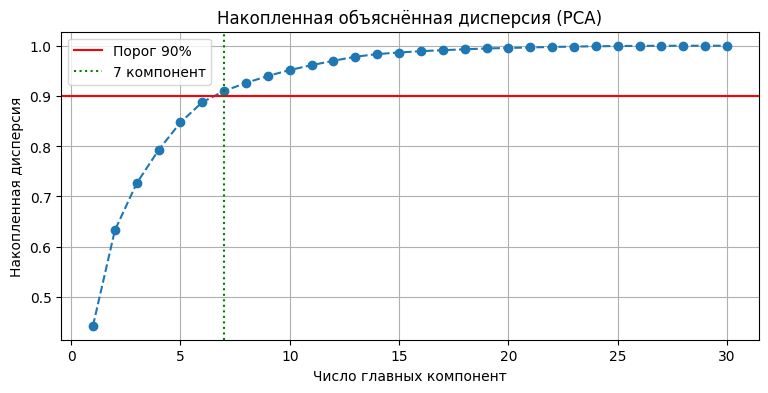

Первые 2 компоненты объясняют 63.24% дисперсии.
Для сохранения 90% дисперсии нужно 7 компонент.


In [4]:
# 1. Обязательное масштабирование перед применением PCA, t-SNE и UMAP
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Обучаем PCA без ограничения компонент для анализа дисперсии
pca_full = PCA()
pca_full.fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

# Находим минимальное число компонент для сохранения 90% дисперсии
n_comp_90 = np.argmax(cum_var >= 0.90) + 1

# 3. Строим график накопленной объяснённой дисперсии
plt.figure(figsize=(9, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o', linestyle='--')
plt.axhline(y=0.90, color='r', linestyle='-', label='Порог 90%')
plt.axvline(x=n_comp_90, color='g', linestyle=':', label=f'{n_comp_90} компонент')
plt.title('Накопленная объяснённая дисперсия (PCA)')
plt.xlabel('Число главных компонент')
plt.ylabel('Накопленная дисперсия')
plt.legend()
plt.grid(True)
plt.show()

print(f"Первые 2 компоненты объясняют {cum_var[1]:.2%} дисперсии.")
print(f"Для сохранения 90% дисперсии нужно {n_comp_90} компонент.")

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


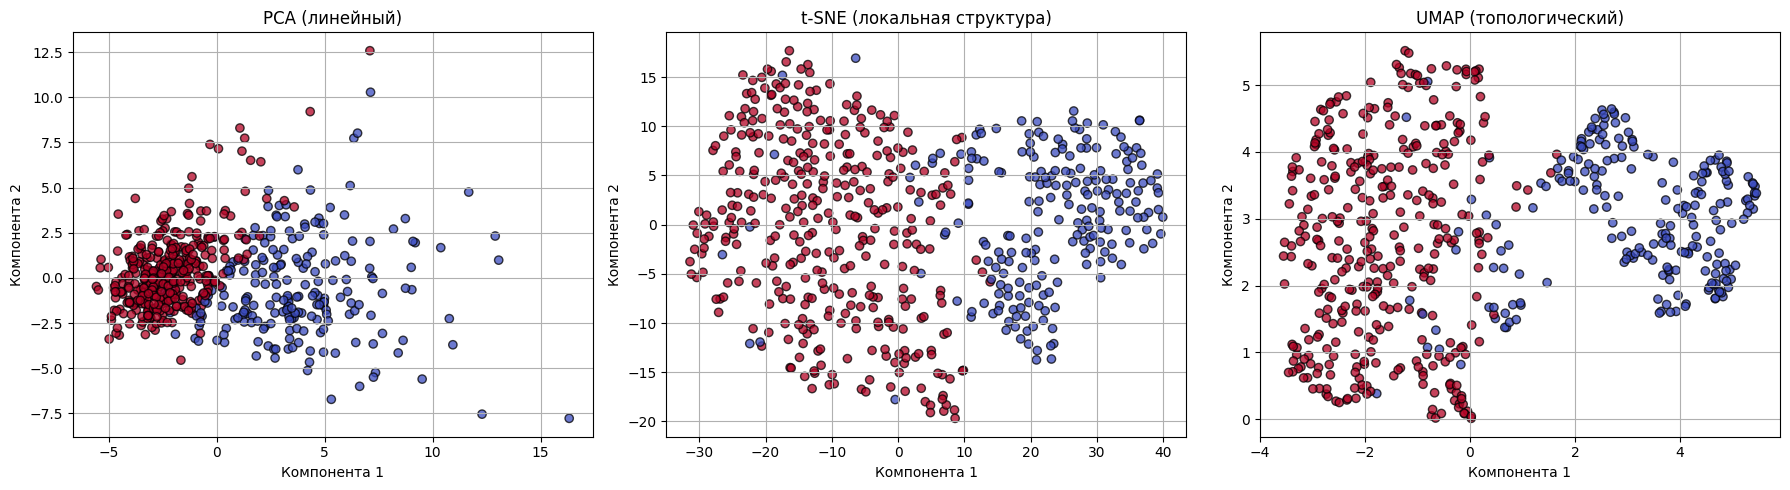

In [5]:
X_pca = PCA(n_components=2, random_state=42).fit_transform(X_scaled)
X_tsne = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X_scaled)
X_umap = umap.UMAP(n_components=2, random_state=42).fit_transform(X_scaled)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
projections = [
    ('PCA (линейный)', X_pca),
    ('t-SNE (локальная структура)', X_tsne),
    ('UMAP (топологический)', X_umap)
]

for ax, (title, proj) in zip(axes, projections):
    ax.scatter(proj[:, 0], proj[:, 1], c=y, cmap='coolwarm', alpha=0.75, edgecolors='k')
    ax.set_title(title)
    ax.set_xlabel('Компонента 1')
    ax.set_ylabel('Компонента 2')
    ax.grid(True)

plt.tight_layout()
plt.show()



In [6]:
pca_model = PCA(n_components=2).fit(X_scaled)
umap_model = umap.UMAP(n_components=2, random_state=42).fit(X_scaled)
tsne_model = TSNE(n_components=2, random_state=42)

print("PCA имеет метод transform:", hasattr(pca_model, 'transform'))
print("UMAP имеет метод transform:", hasattr(umap_model, 'transform'))
print("t-SNE имеет метод transform:", hasattr(tsne_model, 'transform'))

try:
    tsne_model.fit(X_scaled)
    tsne_model.transform(X_scaled[:5])
except AttributeError as e:
    print(f"Ожидаемая ошибка при вызове transform у t-SNE: {e}")


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


PCA имеет метод transform: True
UMAP имеет метод transform: True
t-SNE имеет метод transform: False
Ожидаемая ошибка при вызове transform у t-SNE: 'TSNE' object has no attribute 'transform'


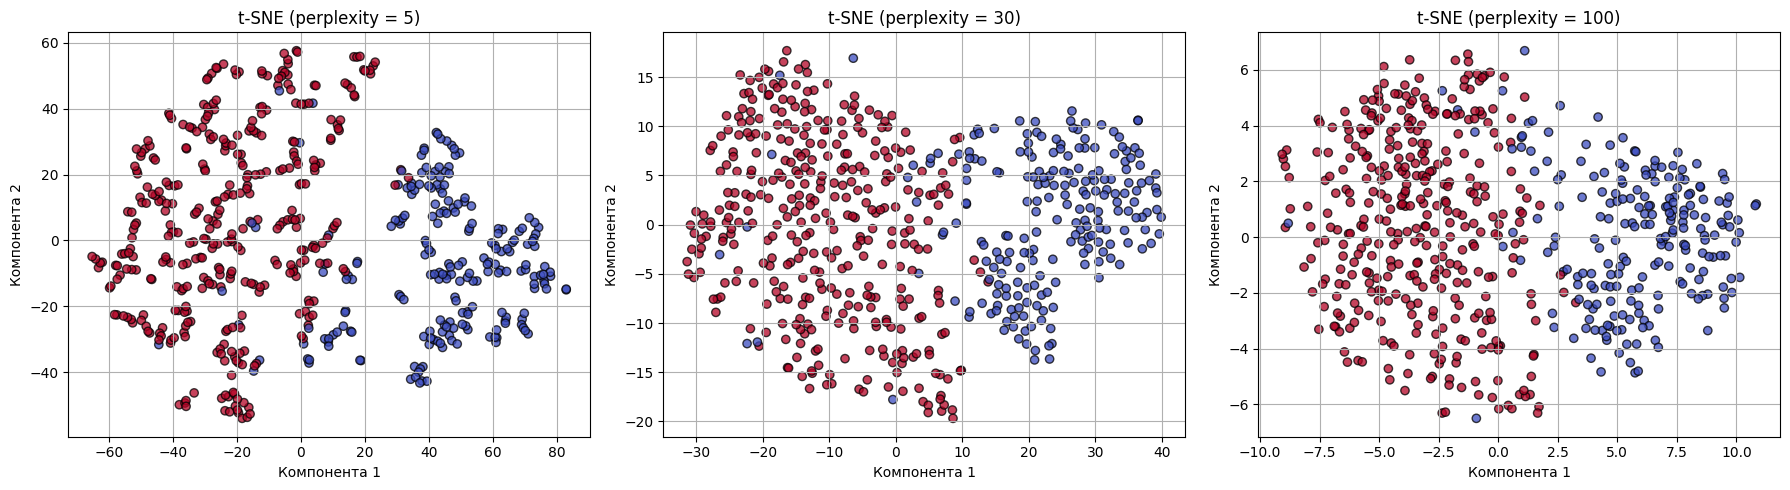

In [7]:
perplexities = [5, 30, 100]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, perp in zip(axes, perplexities):
    X_tsne_p = TSNE(n_components=2, perplexity=perp, random_state=42).fit_transform(X_scaled)
    ax.scatter(X_tsne_p[:, 0], X_tsne_p[:, 1], c=y, cmap='coolwarm', alpha=0.75, edgecolors='k')
    ax.set_title(f't-SNE (perplexity = {perp})')
    ax.set_xlabel('Компонента 1')
    ax.set_ylabel('Компонента 2')
    ax.grid(True)

plt.tight_layout()
plt.show()


## Итоговые выводы по практической работе (Вариант C)

1. **Оправданность применения PCA:**
   * Применение PCA в данной задаче **оправдано**. Исходные 30 признаков сильно скоррелированы, поэтому для сохранения 90 % объяснённой дисперсии достаточно всего **7 главных компонент** (сжатие в 4+ раза без критической потери информации). Первые 2 компоненты объясняют **63.24 %** дисперсии (выше порога 40 %), поэтому даже 2D-проекция информативна.

2. **Сравнение визуализаций (PCA, t-SNE, UMAP):**
   * **PCA** сохраняет глобальную геометрию и линейные расстояния, но классы на границе частично перекрываются.
   * **t-SNE** лучше разделяет классы за счёт стягивания локальных соседей, но искажает глобальные расстояния и размеры кластеров.
   * **UMAP** сочетает чёткое разделение классов (как в t-SNE) с сохранением глобальной структуры данных и работает значительно быстрее.

3. **Устойчивость t-SNE к `perplexity`:**
   * Визуализация t-SNE сильно зависит от `perplexity`: при малом значении (`5`) данные дробятся на множество мелких ложных подкластеров; при оптимальном (`30`) чётко выделяются два основных класса; при большом (`100`) локальная структура сглаживается, а форма облаков меняется.

4. **Применимость в обучающем пайплайне:**
   * **PCA и UMAP** могут входить в обучающий пайплайн (`StandardScaler → PCA/UMAP → Модель`), так как они строят параметрическое/топологическое отображение и имеют метод `.transform()` для корректной проекции новых тестовых объектов без утечки данных.
   * **t-SNE** пригоден **только для визуализации (EDA)**: это непараметрический алгоритм, который напрямую оптимизирует 2D-координаты для текущей выборки и не имеет метода `.transform()` для новых данных.


# Практическая работа № 11. Понижение размерности: PCA, t-SNE и UMAP (Уровень C)

## 🎯 Цель работы
Освоить методы понижения размерности для сжатия признакового пространства и визуализации многомерных данных, провести сравнительный анализ алгоритмов **PCA**, **t-SNE** и **UMAP**, а также определить границы их применимости в пайплайнах машинного обучения.

---

## 📊 Используемый датасет
* **Источник:** `sklearn.datasets.load_breast_cancer`
* **Размерность:** 569 объектов, 30 числовых признаков (соответствует требованию ≥ 10 признаков).
* **Целевая переменная:** бинарная классификация опухолей (злокачественная / доброкачественная).
* **Предобработка:** обязательная стандартизация всех признаков с помощью `StandardScaler` перед применением методов понижения размерности.

---

## 🛠 Выполненные этапы
1. **Анализ объяснённой дисперсии (PCA):**
   * Выполнено масштабирование данных и обучение PCA без ограничения числа компонент.
   * Построен график накопленной объяснённой дисперсии.
   * Определено, что **первые 2 главные компоненты объясняют 63.24 % дисперсии**, а для сохранения **90 % дисперсии достаточно 7 компонент** (сжатие признакового пространства более чем в 4 раза).
2. **Сравнение 2D-проекций (PCA, t-SNE, UMAP):**
   * Построены и сопоставлены двумерные представления одного и того же набора данных для всех трёх алгоритмов.
3. **Проверка индуктивности (метод `.transform()`):**
   * Программно подтверждено наличие `.transform()` у `PCA` и `UMAP` и его отсутствие (`AttributeError`) у `TSNE`.
4. **Анализ устойчивости t-SNE:**
   * Исследовано влияние гиперпараметра `perplexity` на итоговую визуализацию при трёх значениях: `5`, `30` и `100`.

---

## 💡 Основные выводы

### 1. Оправданность применения PCA
Применение PCA в данной задаче **полностью оправдано**: исходные 30 признаков имеют высокую корреляцию, что позволяет сократить размерность до 7 компонент с сохранением 90 % информации, а двумерная проекция (63.24 % дисперсии) остаётся информативной.

### 2. Сравнение визуализаций
* **PCA** сохраняет глобальную геометрию и линейные расстояния между объектами, однако классы на границе частично перекрываются.
* **t-SNE** эффективно стягивает локальных соседей, формируя более чёткую границу между классами, но искажает глобальные расстояния и реальные размеры кластеров.
* **UMAP** сочетает качественное локальное разделение классов (на уровне t-SNE) с лучшим сохранением глобальной топологии данных и высокой скоростью работы.

### 3. Чувствительность t-SNE к `perplexity`
Картина в t-SNE **сильно зависит** от выбора `perplexity`:
* `perplexity = 5`: данные дробятся на множество мелких ложных подкластеров (фокус только на ближайших точках).
* `perplexity = 30`: формируются два чётких, устойчивых кластера, соответствующих реальным классам.
* `perplexity = 100`: локальные детали размываются, а форма и плотность облаков заметно меняются.

### 4. Применимость в обучающем ML-пайплайне
* **PCA и UMAP** могут входить в обучающий пайплайн (`StandardScaler → PCA / UMAP → Модель`), так как строят отображение, позволяющее корректно проецировать новые тестовые объекты через `.transform()` без утечки данных.
* **t-SNE** пригоден **исключительно для разведочного анализа и визуализации (EDA)**: алгоритм является непараметрическим, напрямую оптимизирует 2D-координаты для конкретной выборки и не умеет переносить новые объекты без полного переобучения.

---

## 🚀 Запуск проекта

### В Google Colab
Откройте файл ноутбука `.ipynb` из этого репозитория в Google Colab и последовательно выполните ячейки (библиотека `umap-learn` в Colab предустановлена).

### Локально (Python / WSL)
```bash
pip install numpy pandas matplotlib scikit-learn umap-learn jupyter
jupyter notebook
```
